# 03. Magnitude MP-PCA Denoising — Open QSM Dataset (3-Core Parallel)

`02_Add_noise_Open_QSM_FULL_VOLUME_REVISED.ipynb`에서 생성한
**5-echo noisy complex GRE** 데이터를 magnitude로 변환한 뒤,
DIPY의 MP-PCA를 적용하여 denoising을 수행한다.

이번 버전은 서버의 CPU 3개를 실제로 활용하기 위해
**Noise 10%, 30%, 50%를 서로 다른 프로세스에서 동시에 처리**한다.

실험 원칙:

- 입력: `(X, Y, Z, 5)` noisy complex GRE
- Noise level: 10%, 30%, 50%
- Magnitude 변환 후 MP-PCA 수행
- **10% / 30% / 50%를 3개 프로세스로 병렬 처리**
- **Brain mask는 denoising에 사용하지 않음**
- MP-PCA는 전체 volume에 적용
- Brain mask는 이후 최종 성능평가 ROI용으로만 보관
- Patch radius = 3 → `7 × 7 × 7` spatial patch
- 각 worker는 BLAS thread 1개를 사용하도록 서버 Job에서도 thread 수를 1로 유지


In [1]:
import os
import time
import numpy as np
import scipy.io as sio
from pathlib import Path
import matplotlib.pyplot as plt
import multiprocessing as mp
from concurrent.futures import ProcessPoolExecutor, as_completed


/home/std-202100776/.config/matplotlib is not a writable directory


Matplotlib created a temporary cache directory at /tmp/matplotlib-mkr85xya because there was an issue with the default path (/home/std-202100776/.config/matplotlib); it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.


### 환경설정

Open QSM noisy complex 데이터는 다음 폴더에서 읽는다.

`./data/noisy_data/`

파일명:

- `qsm_siemens_monopolar_noisy_10.npz`
- `qsm_siemens_monopolar_noisy_30.npz`
- `qsm_siemens_monopolar_noisy_50.npz`

Magnitude MP-PCA는 모든 noise level에서 동일한 `PATCH_R=3`을 사용한다.

병렬화는 다음과 같이 수행한다.

```text
Core/Process 1 → Noise 10%
Core/Process 2 → Noise 30%
Core/Process 3 → Noise 50%
```

각 worker가 자기 `.npz` 파일을 직접 읽고 MP-PCA를 수행한 뒤
자기 결과 `.mat` 파일을 직접 저장한다. 따라서 큰 4D 배열을 프로세스 간에 전달하지 않아
메모리 사용과 multiprocessing overhead를 줄인다.


In [2]:
NOISE_LEVELS = [10, 30, 50]

PATCH_R = 3  # 7 x 7 x 7 spatial patch
N_WORKERS = 3

NOISY_DIR = Path("./data/noisy_data").resolve()
OUT_DIR = Path("./data/denoised/magnitude").resolve()

OUT_DIR.mkdir(parents=True, exist_ok=True)

print("Noisy directory :", NOISY_DIR)
print("Output directory:", OUT_DIR)
print("Patch radius    :", PATCH_R)
print("Parallel workers:", N_WORKERS)
print(
    "Patch size      :",
    f"{2 * PATCH_R + 1} x {2 * PATCH_R + 1} x {2 * PATCH_R + 1}"
)


Noisy directory : /home/std-202100776/workspace/data/noisy_data
Output directory: /home/std-202100776/workspace/data/denoised/magnitude
Patch radius    : 3
Parallel workers: 3
Patch size      : 7 x 7 x 7


### 1. 입력 파일 확인

병렬 worker를 시작하기 전에 세 noise level의 입력 파일이 모두 존재하는지만 확인한다.

각 worker는 실행될 때 자기 파일을 직접 불러오므로,
부모 프로세스에서 10%, 30%, 50%의 큰 4D 배열을 모두 메모리에 들고 있지 않는다.


In [3]:
input_paths = {}

for noise_level in NOISE_LEVELS:
    noisy_path = (
        NOISY_DIR /
        f"qsm_siemens_monopolar_noisy_{noise_level}.npz"
    )

    if not noisy_path.exists():
        raise FileNotFoundError(
            f"Noise 파일을 찾을 수 없습니다: {noisy_path}\n"
            "먼저 02_Add_noise_Open_QSM_FULL_VOLUME_REVISED.ipynb를 실행하세요."
        )

    input_paths[noise_level] = noisy_path
    print(f"{noise_level}% 입력 확인 -> {noisy_path}")

print("\n모든 입력 파일 확인 완료")


10% 입력 확인 -> /home/std-202100776/workspace/data/noisy_data/qsm_siemens_monopolar_noisy_10.npz
30% 입력 확인 -> /home/std-202100776/workspace/data/noisy_data/qsm_siemens_monopolar_noisy_30.npz
50% 입력 확인 -> /home/std-202100776/workspace/data/noisy_data/qsm_siemens_monopolar_noisy_50.npz

모든 입력 파일 확인 완료


### 2. 병렬 worker 함수

각 worker는 하나의 noise level만 담당한다.

Worker 내부 처리 순서:

1. `.npz`에서 noisy complex GRE와 metadata 로드
2. complex → magnitude 변환
3. 전체 volume에 Magnitude MP-PCA 수행
4. 결과 `.mat` 저장
5. 완료 정보만 부모 프로세스로 반환

`mask_brain`은 결과 파일에 저장하지만 **MP-PCA에는 전달하지 않는다.**


In [4]:
def run_magnitude_mppca_worker(noise_level, noisy_path_str, out_dir_str, patch_r):
    # worker 내부에서 import하여 각 프로세스가 독립적으로 초기화
    import os
    import time
    import numpy as np
    import scipy.io as sio
    from pathlib import Path
    from dipy.denoise.localpca import mppca

    start_time = time.time()

    noisy_path = Path(noisy_path_str)
    out_dir = Path(out_dir_str)
    out_dir.mkdir(parents=True, exist_ok=True)

    print(
        f"[PID {os.getpid()}] START | Noise {noise_level}% | "
        f"file={noisy_path.name}",
        flush=True
    )

    data = np.load(noisy_path, allow_pickle=False)

    noisy_complex = data["noisy_complex"].astype(np.complex64)
    mask = data["mask_brain"].astype(bool)

    if noisy_complex.ndim != 4:
        raise ValueError(
            f"{noise_level}% noisy_complex는 4D여야 합니다. "
            f"현재 shape={noisy_complex.shape}"
        )

    if noisy_complex.shape[-1] != 5:
        raise ValueError(
            f"{noise_level}% 데이터는 5 echoes를 예상합니다. "
            f"실제={noisy_complex.shape[-1]}"
        )

    if mask.shape != noisy_complex.shape[:3]:
        raise ValueError(
            f"{noise_level}% mask shape {mask.shape} != "
            f"spatial shape {noisy_complex.shape[:3]}"
        )

    # Complex -> Magnitude
    noisy_mag = np.abs(noisy_complex).astype(np.float32)

    # 원본 complex는 더 이상 필요하지 않으므로 worker 메모리에서 해제
    del noisy_complex

    print(
        f"[PID {os.getpid()}] MP-PCA | Noise {noise_level}% | "
        f"shape={noisy_mag.shape} | patch_radius={patch_r} | "
        "mask=NOT_USED | ROI=FULL_VOLUME",
        flush=True
    )

    # 핵심: mask 없이 전체 volume Magnitude MP-PCA
    deno_mag = mppca(
        noisy_mag,
        patch_radius=patch_r
    ).astype(np.float32)

    if deno_mag.shape != noisy_mag.shape:
        raise ValueError(
            f"{noise_level}% denoised shape {deno_mag.shape} "
            f"!= input shape {noisy_mag.shape}"
        )

    output_path = (
        out_dir /
        f"denoised_magnitude_{noise_level}_r{patch_r}.mat"
    )

    save_data = {
        "magnitude_denoised": deno_mag,
        "mask_brain": mask.astype(np.uint8),
        "noise_level": np.int32(noise_level),
        "noise_ratio": np.float32(data["noise_ratio"]),
        "sigma": np.float32(data["sigma"]),
        "seed": np.int32(data["seed"]),
        "overall_mean": np.float32(data["overall_mean"]),
        "patch_radius": np.int32(patch_r),
        "echo_times": (
            data["echo_times"].astype(np.float64)
            if "echo_times" in data.files
            else np.full(5, np.nan, dtype=np.float64)
        ),
        "field_strength": np.float32(
            data["field_strength"]
            if "field_strength" in data.files
            else np.nan
        ),
        "denoise_region": "full_volume",
        "mask_usage": "evaluation_only",
        "parallel_workers": np.int32(3),
        "method": "magnitude_mppca",
    }

    sio.savemat(
        output_path,
        save_data,
        do_compression=True
    )

    elapsed = time.time() - start_time

    print(
        f"[PID {os.getpid()}] DONE  | Noise {noise_level}% | "
        f"{elapsed / 60:.2f} min | {output_path.name}",
        flush=True
    )

    return {
        "noise_level": int(noise_level),
        "output_path": str(output_path),
        "elapsed_sec": float(elapsed),
        "pid": int(os.getpid()),
    }


### 3. 10% / 30% / 50%를 3코어 동시 실행

Linux 서버에서 `fork` multiprocessing context를 사용하여
세 worker를 동시에 실행한다.

중요:

- 서버 Job은 `-c 3`으로 CPU 3개를 요청한다.
- `OMP_NUM_THREADS=1`, `OPENBLAS_NUM_THREADS=1`, `MKL_NUM_THREADS=1`을 유지한다.
- 따라서 **3개 worker × 각 1 thread ≈ CPU 3코어 사용** 구조가 된다.
- 세 noise level은 서로 독립적이므로 알고리즘 결과 정의는 기존 순차 실행과 동일하다.


In [5]:
parallel_start = time.time()
worker_results = {}

# 서버가 Linux이므로 fork context를 명시적으로 사용
ctx = mp.get_context("fork")

print("=" * 70)
print("3-Core Parallel Magnitude MP-PCA 시작")
print(f"Noise levels : {NOISE_LEVELS}")
print(f"Workers      : {N_WORKERS}")
print(f"Patch radius : {PATCH_R}")
print("=" * 70)

with ProcessPoolExecutor(
    max_workers=N_WORKERS,
    mp_context=ctx
) as executor:

    future_to_level = {
        executor.submit(
            run_magnitude_mppca_worker,
            noise_level,
            str(input_paths[noise_level]),
            str(OUT_DIR),
            PATCH_R
        ): noise_level
        for noise_level in NOISE_LEVELS
    }

    for future in as_completed(future_to_level):
        noise_level = future_to_level[future]

        try:
            result = future.result()
            worker_results[noise_level] = result

            print(
                f"MAIN: {noise_level}% 완료 | "
                f"PID={result['pid']} | "
                f"{result['elapsed_sec'] / 60:.2f} min"
            )

        except Exception as e:
            print(f"MAIN: {noise_level}% FAILED -> {repr(e)}")
            raise

parallel_elapsed = time.time() - parallel_start

print("\n" + "=" * 70)
print("모든 noise level 병렬 처리 완료")
print(f"전체 wall time: {parallel_elapsed / 60:.2f} min")
print("=" * 70)

for noise_level in sorted(worker_results):
    print(worker_results[noise_level])


3-Core Parallel Magnitude MP-PCA 시작
Noise levels : [10, 30, 50]
Workers      : 3
Patch radius : 3


[PID 48] START | Noise 50% | file=qsm_siemens_monopolar_noisy_50.npz

[PID 46] START | Noise 10% | file=qsm_siemens_monopolar_noisy_10.npz

[PID 47] START | Noise 30% | file=qsm_siemens_monopolar_noisy_30.npz

[PID 48] MP-PCA | Noise 50% | shape=(176, 256, 144, 5) | patch_radius=3 | mask=NOT_USED | ROI=FULL_VOLUME

[PID 47] MP-PCA | Noise 30% | shape=(176, 256, 144, 5) | patch_radius=3 | mask=NOT_USED | ROI=FULL_VOLUME

... (3 outputs left out)

[PID 47] DONE  | Noise 30% | 12.66 min | denoised_magnitude_30_r3.mat

MAIN: 30% 완료 | PID=47 | 12.66 min


[PID 48] DONE  | Noise 50% | 12.68 min | denoised_magnitude_50_r3.mat

MAIN: 50% 완료 | PID=48 | 12.68 min

모든 noise level 병렬 처리 완료
전체 wall time: 12.69 min
{'noise_level': 10, 'output_path': '/home/std-202100776/workspace/data/denoised/magnitude/denoised_magnitude_10_r3.mat', 'elapsed_sec': 755.7784814834595, 'pid': 46}
{'noise_level': 30, 'output_path': '/home/std-202100776/workspace/data/denoised/magnitude/denoised_magnitude_30_r3.mat', 'elapsed_sec': 759.8193089962006, 'pid': 47}
{'noise_level': 50, 'output_path': '/home/std-202100776/workspace/data/denoised/magnitude/denoised_magnitude_50_r3.mat', 'elapsed_sec': 760.641877412796, 'pid': 48}


### 4. 저장 결과 확인

각 worker가 직접 다음 파일을 저장한다.

- `denoised_magnitude_10_r3.mat`
- `denoised_magnitude_30_r3.mat`
- `denoised_magnitude_50_r3.mat`

저장 내용과 실험 조건은 기존 순차 버전과 동일하며,
추가로 병렬 worker 수 metadata만 기록한다.


In [6]:
output_paths = {}

for noise_level in NOISE_LEVELS:
    output_path = (
        OUT_DIR /
        f"denoised_magnitude_{noise_level}_r{PATCH_R}.mat"
    )

    if not output_path.exists():
        raise FileNotFoundError(
            f"{noise_level}% 결과 파일이 생성되지 않았습니다: {output_path}"
        )

    output_paths[noise_level] = output_path

    size_mb = output_path.stat().st_size / (1024 ** 2)
    print(
        f"{noise_level}% 결과 확인 | "
        f"{output_path.name} | {size_mb:.1f} MB"
    )


10% 결과 확인 | denoised_magnitude_10_r3.mat | 107.1 MB
30% 결과 확인 | denoised_magnitude_30_r3.mat | 105.7 MB
50% 결과 확인 | denoised_magnitude_50_r3.mat | 105.2 MB


### 5. Denoising 결과 확인

메모리 사용을 줄이기 위해 visualization 시점에
noise level 하나씩 noisy `.npz`와 denoised `.mat`을 다시 읽는다.

비교:

- Noisy Magnitude
- Denoised Magnitude
- Removed component = `Noisy - Denoised`

Removed component는 **최종 error map이 아니다.**
MP-PCA가 입력 영상에서 제거한 성분을 확인하기 위한 시각화이다.

최종 PSNR / SSIM / NRMSE / HFEN 평가는 별도 평가 notebook에서
clean reference와 brain mask를 사용한다.


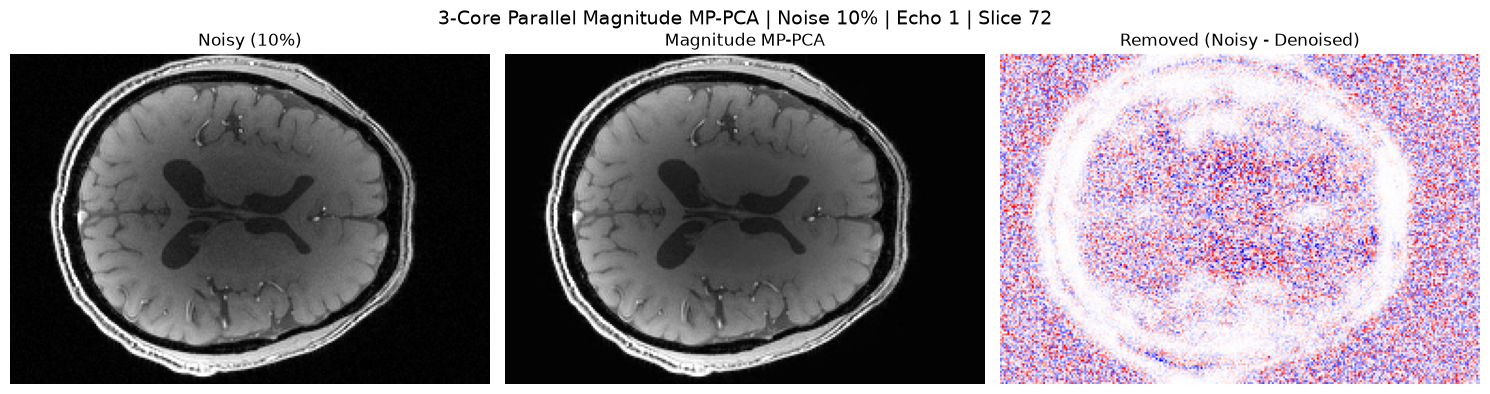

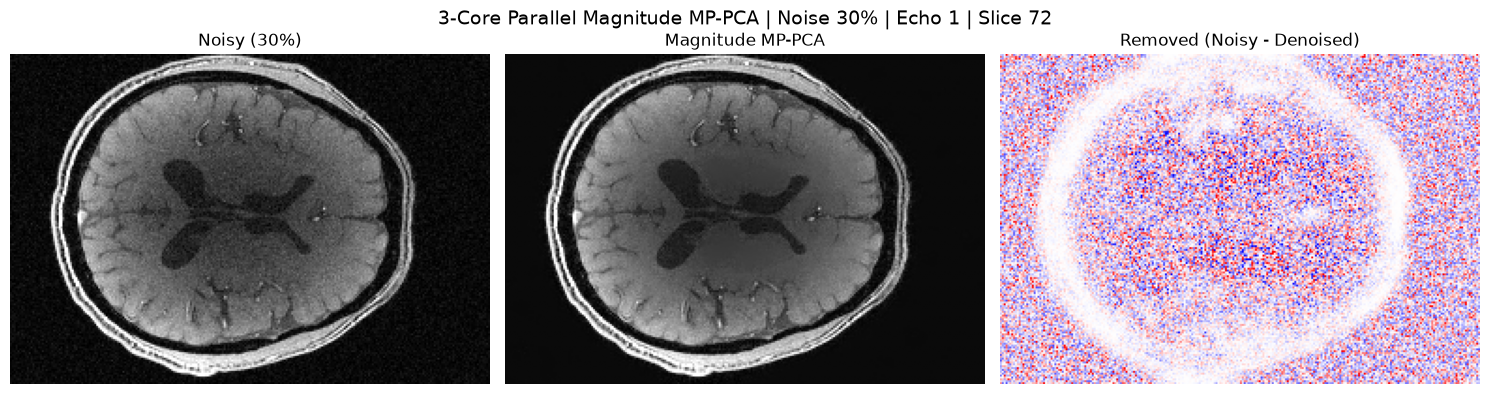

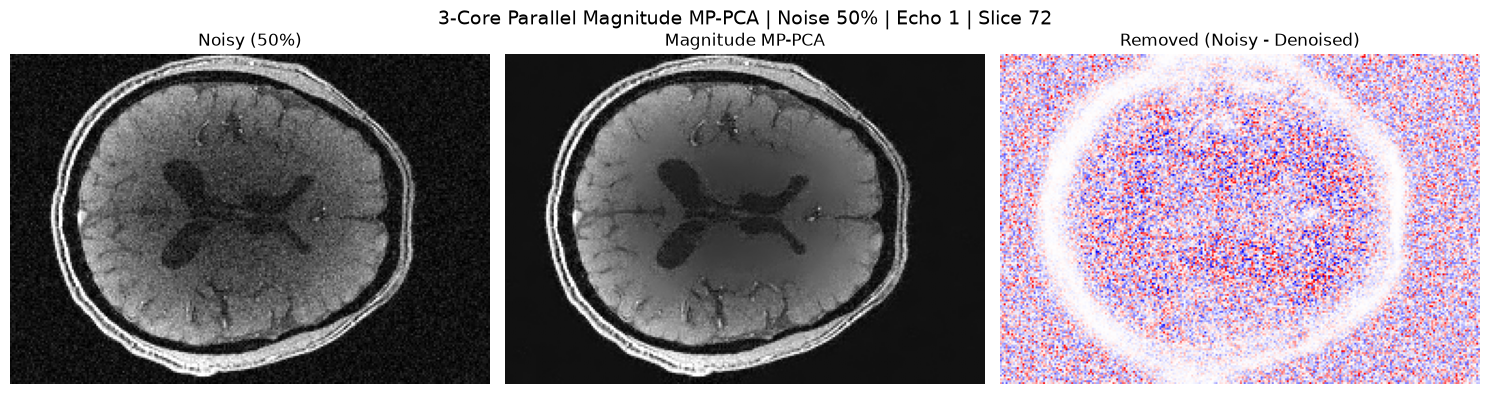

In [7]:
echo_idx = 0

for noise_level in NOISE_LEVELS:
    noisy_npz = np.load(input_paths[noise_level], allow_pickle=False)
    noisy_complex = noisy_npz["noisy_complex"].astype(np.complex64)
    noisy_mag = np.abs(noisy_complex).astype(np.float32)

    mat = sio.loadmat(output_paths[noise_level])
    deno_mag = mat["magnitude_denoised"].astype(np.float32)

    if deno_mag.shape != noisy_mag.shape:
        raise ValueError(
            f"{noise_level}% visualization shape mismatch: "
            f"{deno_mag.shape} != {noisy_mag.shape}"
        )

    slice_idx = noisy_mag.shape[2] // 2

    noisy_2d = noisy_mag[:, :, slice_idx, echo_idx]
    deno_2d = deno_mag[:, :, slice_idx, echo_idx]
    removed_2d = noisy_2d - deno_2d

    vmin, vmax = np.percentile(noisy_2d, (1, 99))

    dv = float(np.percentile(np.abs(removed_2d), 99))
    dv = max(dv, 1e-8)

    fig, ax = plt.subplots(1, 3, figsize=(15, 4))

    ax[0].imshow(
        noisy_2d,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    ax[0].set_title(f"Noisy ({noise_level}%)")

    ax[1].imshow(
        deno_2d,
        cmap="gray",
        vmin=vmin,
        vmax=vmax
    )
    ax[1].set_title("Magnitude MP-PCA")

    ax[2].imshow(
        removed_2d,
        cmap="bwr",
        vmin=-dv,
        vmax=dv
    )
    ax[2].set_title("Removed (Noisy - Denoised)")

    for a in ax:
        a.axis("off")

    fig.suptitle(
        f"3-Core Parallel Magnitude MP-PCA | "
        f"Noise {noise_level}% | Echo {echo_idx + 1} | Slice {slice_idx}",
        fontsize=14
    )

    plt.tight_layout()
    plt.show()

    # 다음 noise level 전에 큰 배열 참조 제거
    del noisy_complex, noisy_mag, deno_mag, mat
